# Figure 4 - FS-peptide as a model system

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** The FS-peptide (Ace-A5(AAARA)3A-Nme, 21 residues) is a classic transiently helical peptide. Panel B is the per-residue Hellinger distance between the full-Hamiltonian (FH) and excluded-volume (EV) joint φ/ψ distributions; C is the all-to-all comparison between FH replicates; D is the spread of B; E is the per-residue fractional helicity.

**What to look for.** The central residues (roughly 4-13) sit furthest from the EV limit (B), and that is exactly where the fractional helicity peaks (E) - the restriction is helix formation. Crucially, the all-to-all comparison (C) is low and flat (~0.2 everywhere), so every replicate sees the same restriction: this is reproducible structure, not a trap. Figure 5 shows what the same peptide looks like when a region *is* trapped.

**Data.** 20 CAMPARI/ABSINTH Monte Carlo replicates (10 from a coil start, 10 from a helical start; 3000 frames each) and 20 matching EV replicates. The bin width is the manuscript default of 15°; Figures S5-S12 (notebook 09) explore other widths.

**Figure 3** of the paper is a flowchart made in a vector graphics editor and has no notebook.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Load the simulations

`load_system` walks the `data/fs_peptide/full/` and `data/fs_peptide/ev/` folders for numbered replicate directories containing `__traj.xtc` + `__START.pdb`, then builds a `SamplingQuality` object. On construction that object loads every trajectory, extracts chain 0, and computes φ and ψ for every frame of every replicate and reference - so this cell does the heavy lifting; the plots below are cheap.

In [2]:
fs_qual = load_system("fs_peptide/full", "fs_peptide/ev", num_replicates=10,
                      method="2D angle distributions", bwidth_degrees=15)
sequence = print_sequence(fs_qual)

20 FH replicates, 20 EV replicates


AAAAAAAARAAAARAAAARAA
.........1.........2.


## How to read a PENGUIN figure

Every PENGUIN summary has the same four panels (the sequence cartoon shown as panel **A** in the paper was drawn in a vector graphics editor, so here we print the sequence with a ruler instead):

* **B - Comparison to the excluded-volume limit.** For every residue and every full-Hamiltonian (FH) replicate, the joint (φ, ψ) distribution is histogrammed and compared to the same residue in the excluded-volume (EV) reference ensemble using the Hellinger distance (0 = identical, 1 = no overlap). Red points are individual replicates; the black line is the replicate mean. Low values mean the residue explores its backbone conformational space about as freely as a chain with no attractive interactions; high values mean the FH ensemble is restricted relative to that limit - which can be genuine structure *or* an energetic trap.
* **C - All-to-all trajectory comparison.** The same Hellinger distance, but between every pair of FH replicates. If independent replicates agree with one another (low values) the restriction seen in **B** is reproducible and therefore reflects the Hamiltonian; if they disagree (high values) each replicate is stuck somewhere different - the signature of poor sampling.
* **D - Spread of B.** The maximum minus minimum Hellinger distance across replicates, per residue; a compact summary of how consistently a residue is scored against the EV limit.
* **E - Fractional helicity.** Per-residue DSSP helicity of the FH replicates, so that any restriction in **B** can be checked against a concrete structural explanation.

The logic of the method is that **B** on its own cannot distinguish folding from trapping, but **B** together with **C** can: reproducible structure gives high **B** / low **C**, whereas energetic traps give high **B** / high **C**.

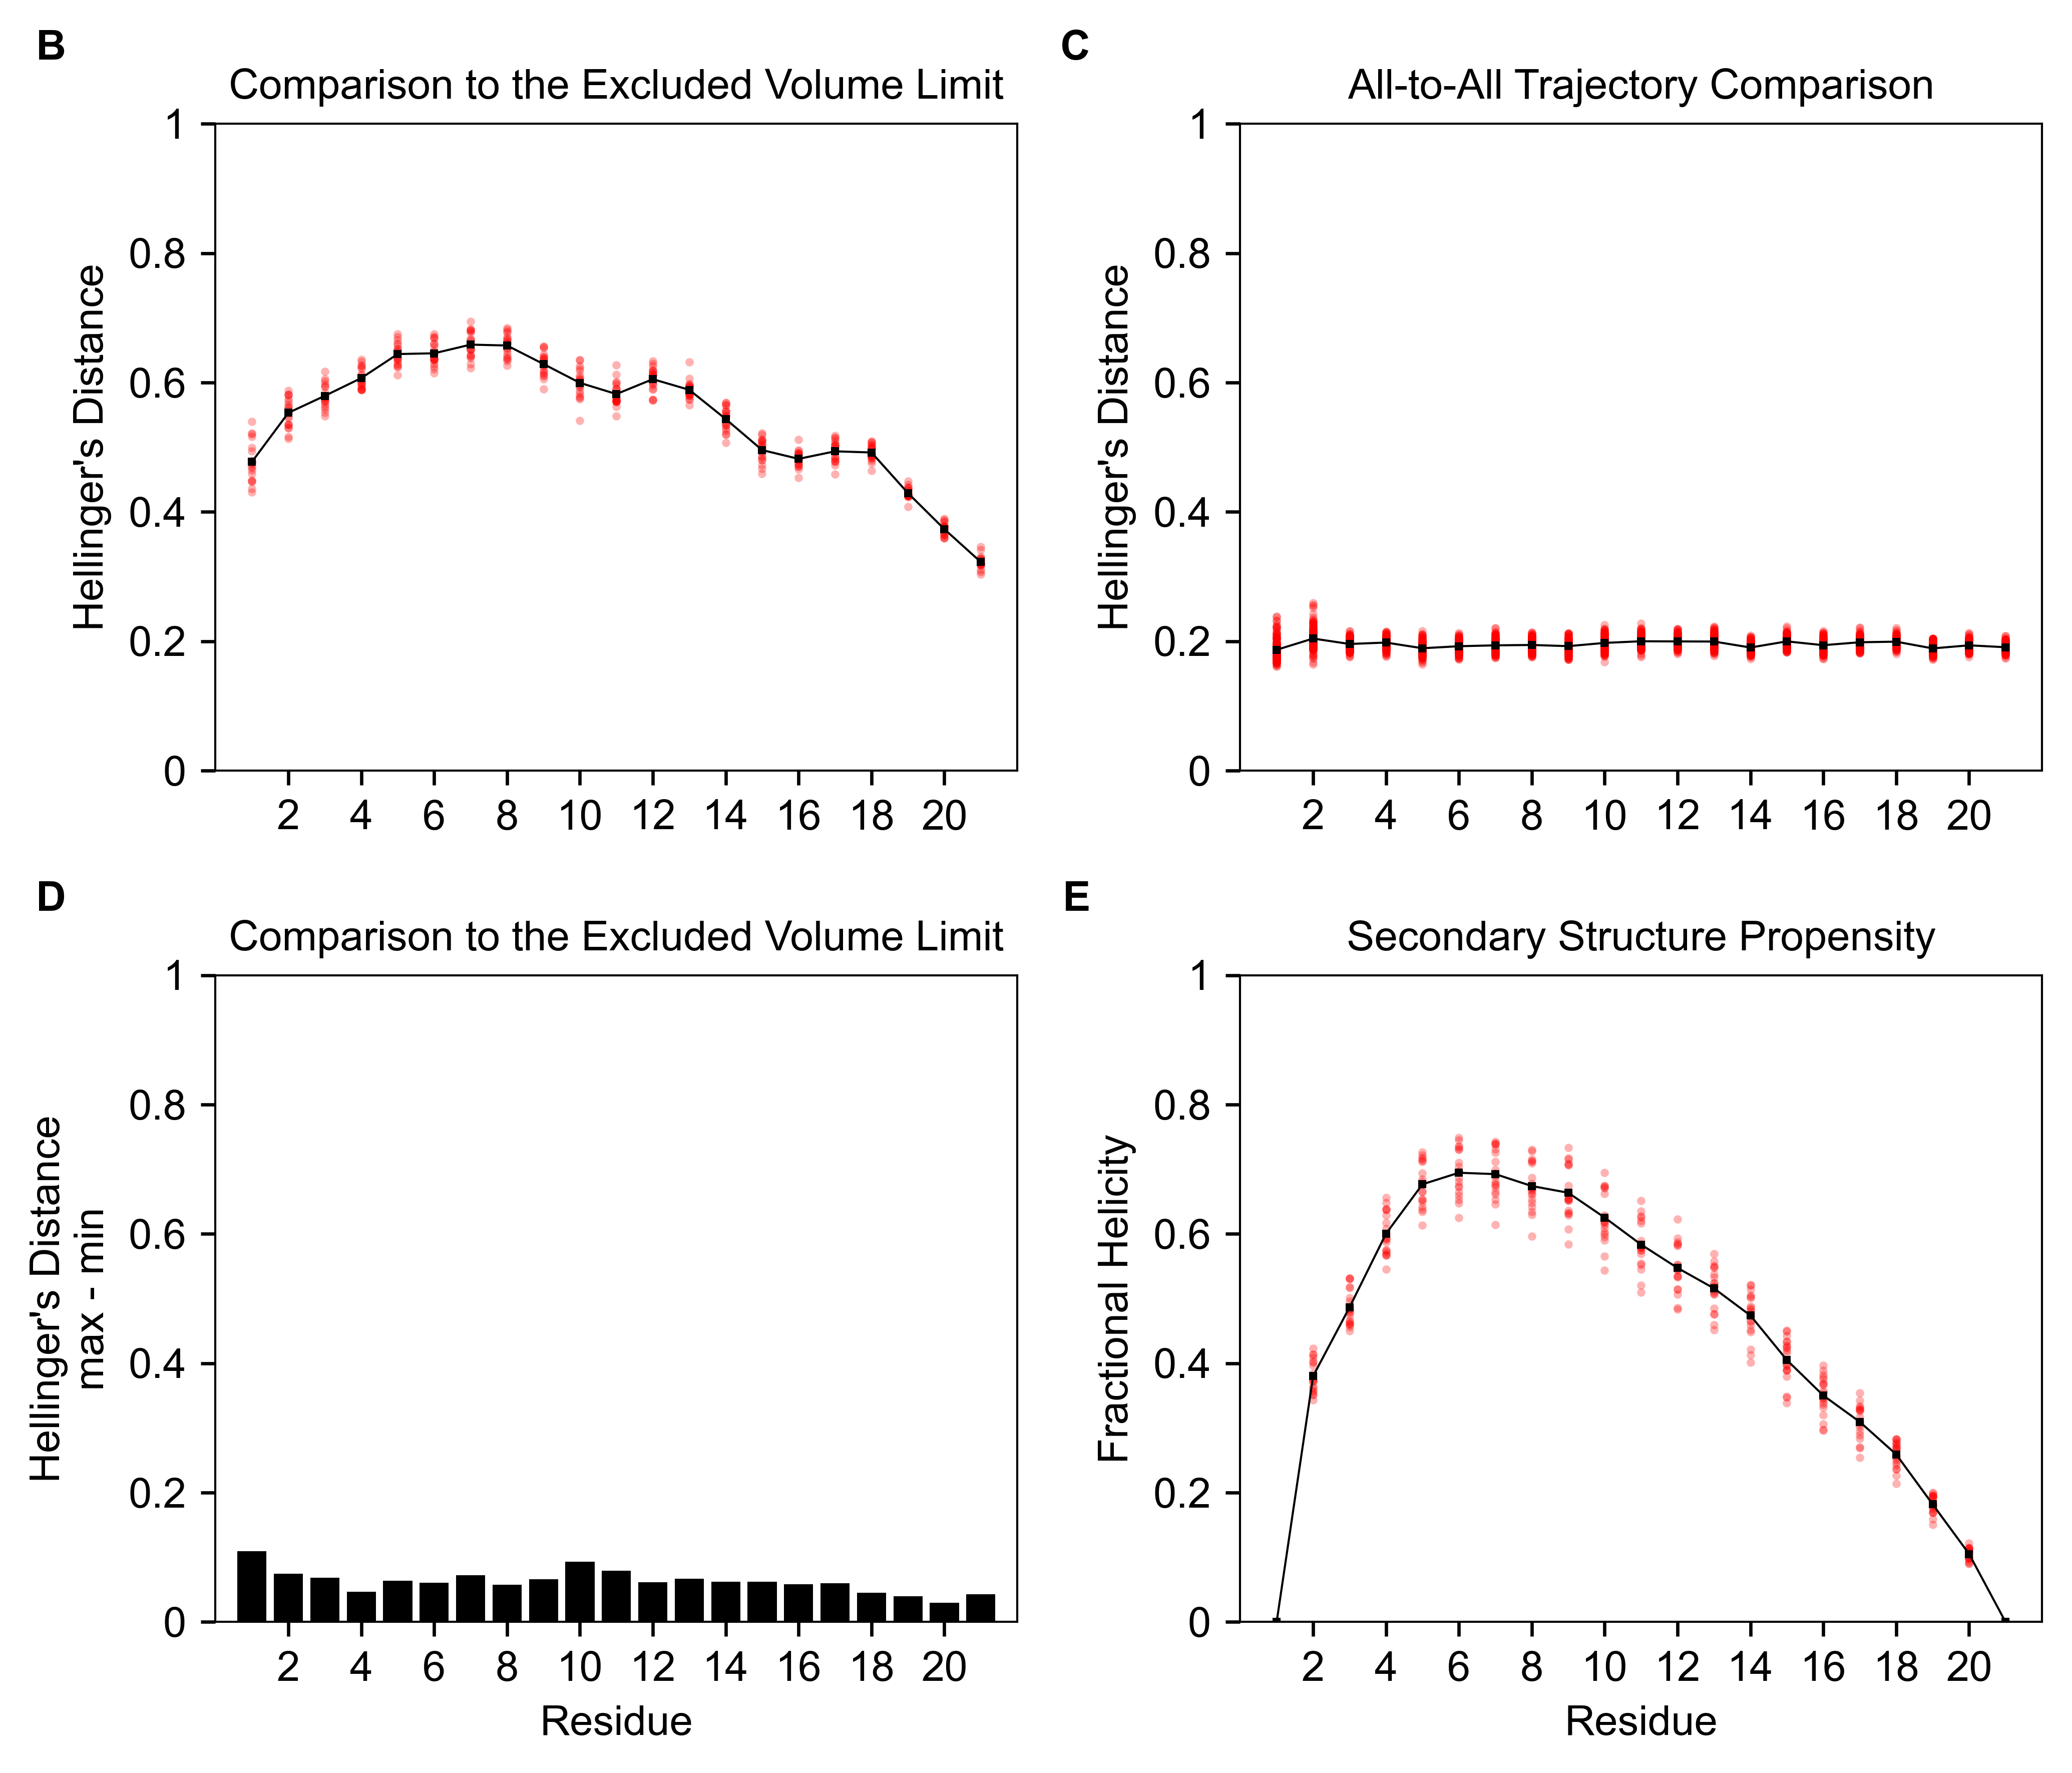

In [3]:
fig, axd = penguin_figure(fs_qual, dihedral="2D", increment=2, figsize=(7, 6), fontsize=10,
                          save_path=figure_path("fig4", "fs_qual_2D_hellingers.pdf"))

## The numbers behind the panels

`hellingers_distances()` returns the (replicates x residues) matrix plotted in panel B; the replicate mean is what the paper reports as the per-residue value.

In [4]:
H = np.asarray(fs_qual.hellingers_distances())
print("shape (replicates, residues):", H.shape)
print("replicate-mean Hellinger distance per residue:")
for res, aa, h in zip(range(1, H.shape[1] + 1), sequence, H.mean(axis=0)):
    print(f"  {res:2d} {aa}  {h:.2f}")

shape (replicates, residues): (20, 21)
replicate-mean Hellinger distance per residue:
   1 A  0.48
   2 A  0.55
   3 A  0.58
   4 A  0.61
   5 A  0.64
   6 A  0.65
   7 A  0.66
   8 A  0.66
   9 R  0.63
  10 A  0.60
  11 A  0.58
  12 A  0.61
  13 A  0.59
  14 R  0.54
  15 A  0.50
  16 A  0.48
  17 A  0.49
  18 A  0.49
  19 R  0.43
  20 A  0.37
  21 A  0.32
